# Patents and Industrial Expansion in Nineteenth-Century Britain

I am interested in how the rules surrounding invention relate to changes in industry. This analysis follows sealed patents, coal production, and newly opened railway mileage around the 1852 patent reform.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT / "src/industry.py").exists():
    raise RuntimeError("Open this notebook from the project folder")
sys.path.insert(0, str(ROOT / "src"))
from industry import (download_sources, load_panel, summarize_growth, analyze_reform,
                      correlation_analysis, expanding_evaluation, save_table, LABELS)
plt.rcParams.update({"figure.dpi": 120, "savefig.dpi": 180, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.grid": True,
                     "grid.alpha": .18})
COLORS = {"sealed": "#344F80", "applications": "#A5B4D0", "coal": "#B27643", "rail": "#31827A"}
FIGURES = ROOT / "outputs/figures"
FIGURES.mkdir(parents=True, exist_ok=True)
def finish_figure(fig, name):
    fig.savefig(FIGURES / name, bbox_inches="tight")
    plt.show()
    plt.close(fig)

In [2]:
source_checks = download_sources(ROOT)
display(source_checks[["source", "mode", "http_status", "bytes", "rows", "schema_valid"]])
panel, coverage, raw_frames = load_panel(ROOT)
(ROOT / "data/processed").mkdir(parents=True, exist_ok=True)
panel.to_csv(ROOT / "data/processed/annual_panel.csv", index=True)
save_table(coverage, ROOT, "coverage")
display(coverage)

,source,mode,http_status,bytes,rows,schema_valid
0,patents,bundled_snapshot,None,13878,322,True
1,coal,bundled_snapshot,None,1178,68,True
2,rail,bundled_snapshot,None,1621,110,True


,indicator,first_year,last_year,observed_years,missing_inside_span
0,Sealed patents,1802,1902,101,0
1,Patent applications,1852,1902,51,0
2,Coal output,1854,1902,49,0
3,New railway mileage,1826,1902,74,3


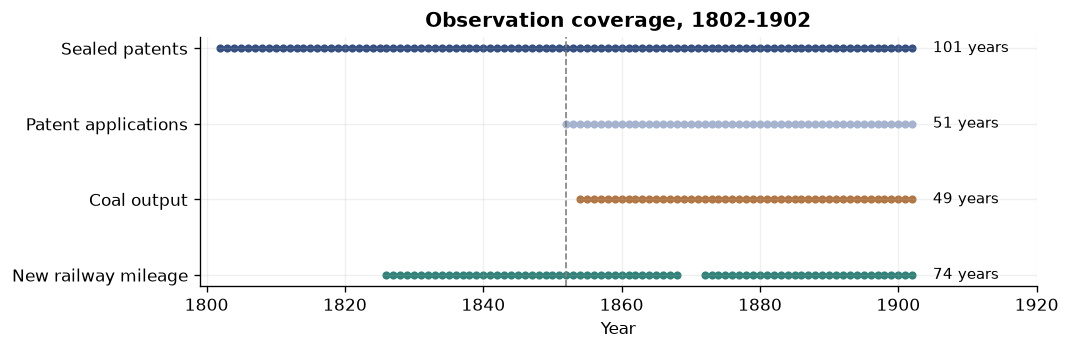

In [3]:
fig, ax = plt.subplots(figsize=(9, 2.7))
for i, column in enumerate(["sealed", "applications", "coal", "rail"]):
    valid = panel[column].dropna()
    ax.scatter(valid.index, np.full(len(valid), i), s=15, color=COLORS[column])
    ax.text(1905, i, f"{len(valid)} years", va="center", fontsize=9)
ax.axvline(1852, color="grey", ls="--", lw=1)
ax.set(yticks=range(4), yticklabels=[LABELS[c] for c in ["sealed", "applications", "coal", "rail"]],
       xlim=(1799, 1920), xlabel="Year", title="Observation coverage, 1802-1902")
ax.invert_yaxis()
finish_figure(fig, "coverage.png")

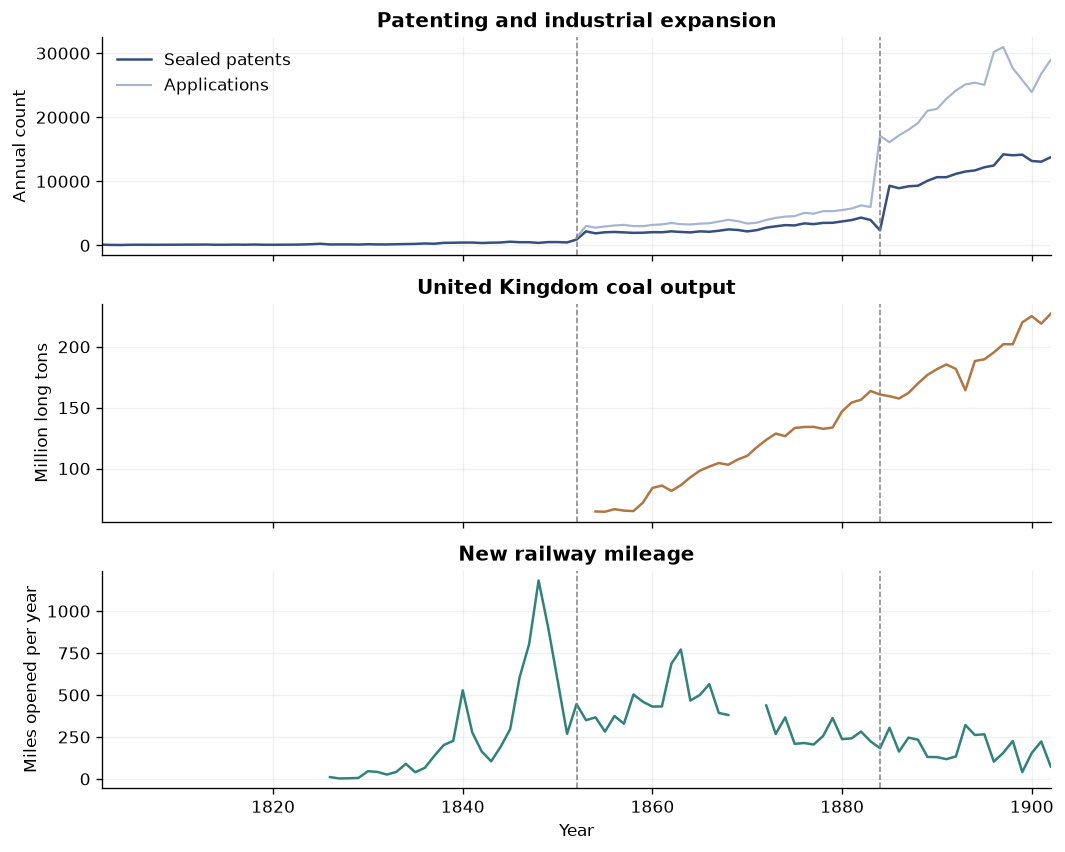

In [11]:
fig, axes = plt.subplots(3, 1, figsize=(9, 7.2), sharex=True)
axes[0].plot(panel.index, panel.sealed, color=COLORS["sealed"], label="Sealed patents")
axes[0].plot(panel.index, panel.applications, color=COLORS["applications"], label="Applications", lw=1.3)
axes[0].set(ylabel="Annual count", title="Patenting and industrial expansion")
axes[0].legend(frameon=False, loc="upper left")
axes[1].plot(panel.index, panel.coal, color=COLORS["coal"])
axes[1].set(ylabel="Million long tons", title="United Kingdom coal output")
axes[2].plot(panel.index, panel.rail, color=COLORS["rail"])
axes[2].set(ylabel="Miles opened per year", xlabel="Year", title="New railway mileage")
for ax in axes:
    for year in [1852, 1884]: ax.axvline(year, color="grey", ls="--", lw=.9)
    ax.set_xlim(1802, 1902)
fig.tight_layout()
finish_figure(fig, "historical_series.png")

In [12]:
growth, local_means = summarize_growth(panel)
save_table(growth, ROOT, "endpoint_growth")
save_table(local_means, ROOT, "local_means")
display(growth.round(3))
display(local_means.round(3))

,indicator,start,end,start_value,end_value,cagr_pct
0,Sealed patents,1802,1851,107.0,455.0,2.998
1,Sealed patents,1853,1902,2187.0,13764.0,3.825
2,Coal output,1854,1878,64.7,132.6,3.035
3,Coal output,1878,1902,132.6,227.1,2.267


,indicator,start,end,n,annual_mean
0,Sealed patents,1845,1851,7,489.714
1,New railway mileage,1845,1851,7,664.286
2,Sealed patents,1853,1859,7,2023.429
3,New railway mileage,1853,1859,7,380.857


,model,first_post_year,parameters,bic,rmse_log
0,Single trend,NaN,2,-163.495,0.341
1,Reform date,1853.0,4,-246.135,0.192
2,Scanned date,1853.0,5,-241.753,0.192


,n,best_first_post_year,jump_pct,pre_trend_pct,post_trend_pct
0,80,1853,218.137,4.205,2.642


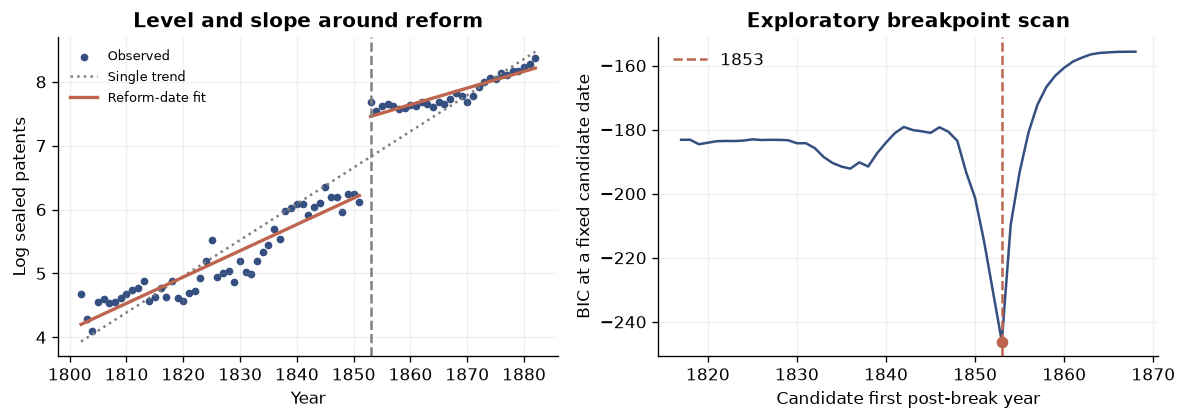

In [13]:
reform_sample, single_trend, reform_fit, break_scan, reform_models, reform_summary = analyze_reform(panel)
save_table(reform_models, ROOT, "reform_models")
save_table(break_scan, ROOT, "breakpoint_scan")
display(reform_models.round(3))
display(pd.DataFrame([reform_summary]).round(3))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
axes[0].scatter(reform_sample.index, np.log(reform_sample), s=13, color=COLORS["sealed"], label="Observed")
axes[0].plot(reform_sample.index, single_trend["fitted"], color="grey", ls=":", label="Single trend")
before = reform_sample.index < 1853
for mask in [before, ~before]:
    axes[0].plot(reform_sample.index[mask], reform_fit["fitted"][mask], color="#BD654E", lw=2,
                 label="Reform-date fit" if mask is before else None)
axes[0].axvline(1853, color="grey", ls="--")
axes[0].set(xlabel="Year", ylabel="Log sealed patents", title="Level and slope around reform")
axes[0].legend(frameon=False, fontsize=8)
axes[1].plot(break_scan.first_post_year, break_scan.bic_fixed_date, color=COLORS["sealed"])
axes[1].axvline(1853, color="#BD654E", ls="--", label="1853")
axes[1].scatter([reform_summary["best_first_post_year"]], [break_scan.bic_fixed_date.min()], color="#BD654E", zorder=3)
axes[1].set(xlabel="Candidate first post-break year", ylabel="BIC at a fixed candidate date", title="Exploratory breakpoint scan")
axes[1].legend(frameon=False)
fig.tight_layout()
finish_figure(fig, "patent_reform.png")

,target,representation,n,r
0,Coal output,Log levels,49,0.883
1,Coal output,Detrended log levels,49,-0.623
2,Coal output,Annual log changes,48,-0.052
3,New railway mileage,Log levels,46,-0.735
4,New railway mileage,Detrended log levels,46,-0.105
5,New railway mileage,Annual log changes,45,0.151


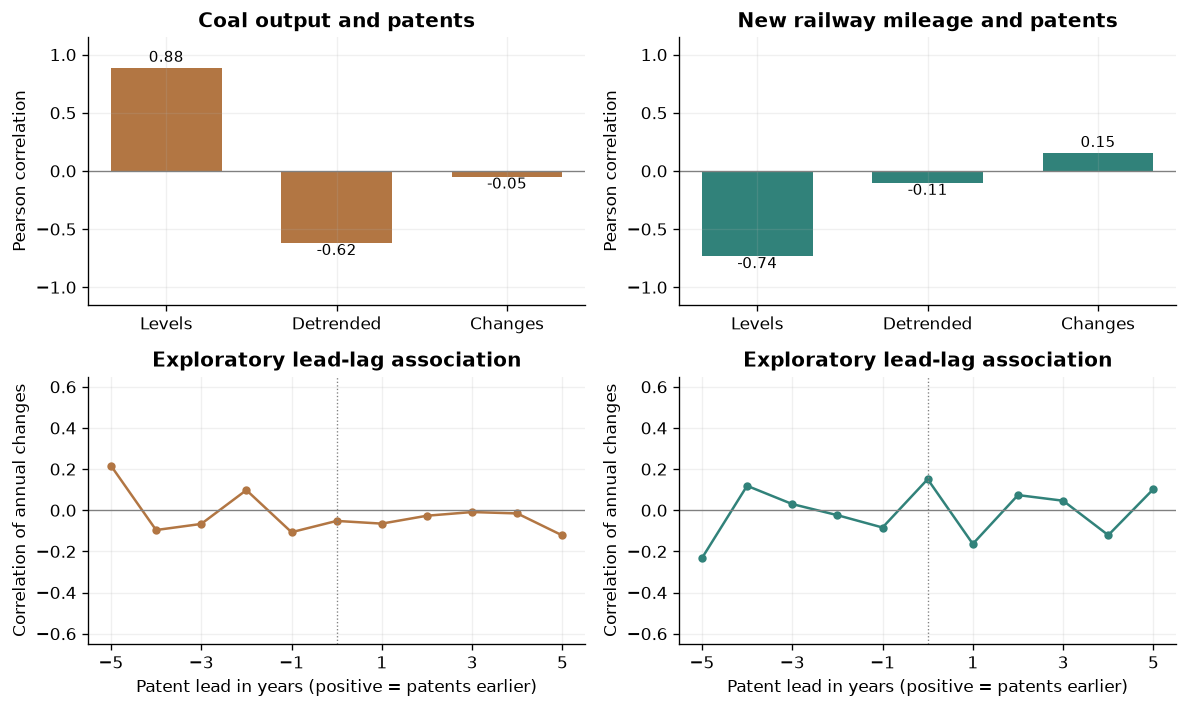

In [14]:
correlations, lag_correlations = correlation_analysis(panel)
save_table(correlations, ROOT, "correlations")
save_table(lag_correlations, ROOT, "lag_correlations")
display(correlations.round(3))
fig, axes = plt.subplots(2, 2, figsize=(10, 6.0))
representations = ["Log levels", "Detrended log levels", "Annual log changes"]
for j, (target, color) in enumerate([("Coal output", COLORS["coal"]), ("New railway mileage", COLORS["rail"])]):
    rows = correlations[correlations.target == target].set_index("representation").loc[representations]
    bars = axes[0,j].bar(range(3), rows.r, color=color, width=.65)
    for bar, value in zip(bars, rows.r):
        axes[0,j].text(bar.get_x()+bar.get_width()/2, value + (.055 if value >= 0 else -.1),
                       f"{value:.2f}", ha="center", fontsize=9)
    axes[0,j].axhline(0, color="grey", lw=.8)
    axes[0,j].set(xticks=range(3), xticklabels=["Levels", "Detrended", "Changes"], ylim=(-1.15,1.15),
                  ylabel="Pearson correlation", title=target + " and patents")
    lag_rows = lag_correlations[lag_correlations.target == target]
    axes[1,j].plot(lag_rows.patent_lead_years, lag_rows.r, marker="o", ms=4, color=color)
    axes[1,j].axhline(0, color="grey", lw=.8)
    axes[1,j].axvline(0, color="grey", ls=":", lw=.8)
    axes[1,j].set(xlabel="Patent lead in years (positive = patents earlier)", ylabel="Correlation of annual changes",
                  xticks=range(-5,6,2), ylim=(-.65,.65), title="Exploratory lead-lag association")
fig.tight_layout()
finish_figure(fig, "associations.png")

,target,model,test_n,first_test,last_test,mae,rmse
0,coal_growth,Historical mean,27,1876,1902,3.310,4.537
1,coal_growth,Own lag + time,27,1876,1902,3.353,4.880
2,coal_growth,Own lag + time + patents,27,1876,1902,3.569,5.061
3,rail,Historical mean,25,1878,1902,146.515,161.554
4,rail,Own lag + time,25,1878,1902,67.632,80.910
5,rail,Own lag + time + patents,25,1878,1902,62.660,77.575


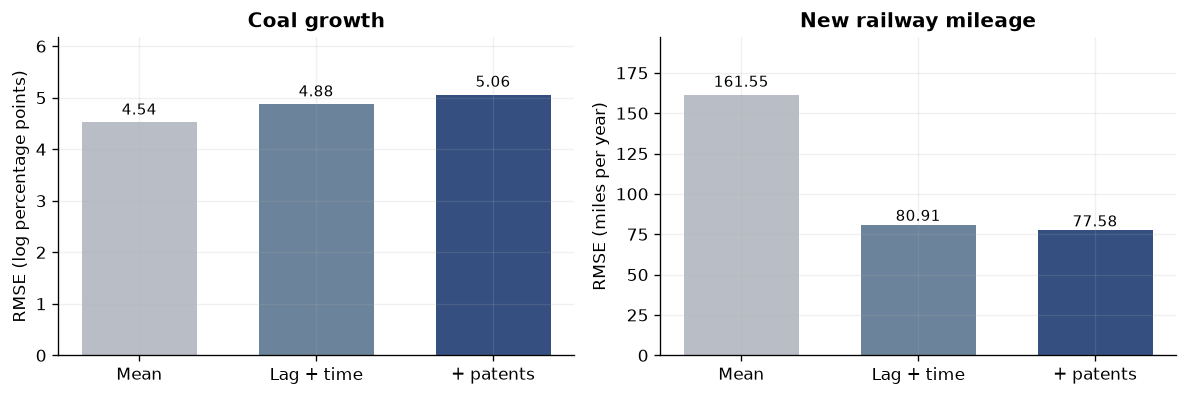

In [8]:
predictions, forecast_metrics = expanding_evaluation(panel, min_train=20)
save_table(predictions, ROOT, "forecast_predictions")
save_table(forecast_metrics, ROOT, "forecast_metrics")
display(forecast_metrics.round(3))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
names = ["Historical mean", "Own lag + time", "Own lag + time + patents"]
for ax, target, title, unit in zip(axes, ["coal_growth", "rail"], ["Coal growth", "New railway mileage"],
                                  ["RMSE (log percentage points)", "RMSE (miles per year)"]):
    rows = forecast_metrics[forecast_metrics.target == target].set_index("model").loc[names]
    bars = ax.bar(range(3), rows.rmse, color=["#B9BEC6", "#6B839B", "#344F80"], width=.65)
    for bar,value in zip(bars, rows.rmse):
        ax.text(bar.get_x()+bar.get_width()/2, value*1.03, f"{value:.2f}", ha="center", fontsize=9)
    ax.set(xticks=range(3), xticklabels=["Mean", "Lag + time", "+ patents"], ylabel=unit, title=title,
           ylim=(0, rows.rmse.max()*1.22))
fig.tight_layout()
finish_figure(fig, "forecast_errors.png")

,target,initial_training_n,test_n,rmse_without_patents,rmse_with_patents,rmse_change_pct
0,coal_growth,15,32,4.669,4.822,3.271
1,rail,15,30,93.272,91.313,-2.100
2,coal_growth,20,27,4.880,5.061,3.717
3,rail,20,25,80.910,77.575,-4.121
4,coal_growth,25,22,5.001,5.198,3.929
5,rail,25,20,83.726,79.633,-4.888


,target,sample,n,r
0,Coal output,All available changes,48,-0.052
1,New railway mileage,All available changes,45,0.151
2,Coal output,Event pairs removed,43,-0.017
3,New railway mileage,Event pairs removed,40,-0.108


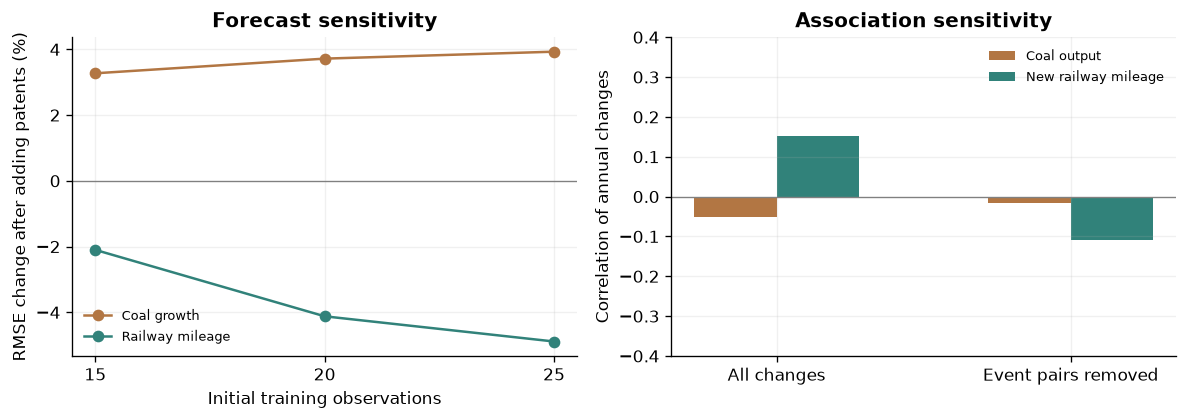

In [9]:
sensitivity_rows = []
for initial in [15, 20, 25]:
    _, metrics = expanding_evaluation(panel, min_train=initial)
    for target in ["coal_growth", "rail"]:
        rows = metrics[metrics.target == target].set_index("model")
        base_rmse = rows.loc["Own lag + time", "rmse"]
        extended_rmse = rows.loc["Own lag + time + patents", "rmse"]
        sensitivity_rows.append({"target": target, "initial_training_n": initial,
                                 "test_n": int(rows.loc["Own lag + time", "test_n"]),
                                 "rmse_without_patents": base_rmse, "rmse_with_patents": extended_rmse,
                                 "rmse_change_pct": 100*(extended_rmse/base_rmse-1)})
forecast_sensitivity = pd.DataFrame(sensitivity_rows)
save_table(forecast_sensitivity, ROOT, "forecast_sensitivity")
display(forecast_sensitivity.round(3))
event_years = [1884,1885,1886,1893,1894]
event_correlations, _ = correlation_analysis(panel, exclude_years=event_years)
change_full = correlations[correlations.representation == "Annual log changes"].copy()
change_full["sample"] = "All available changes"
change_event = event_correlations[event_correlations.representation == "Annual log changes"].copy()
change_event["sample"] = "Event pairs removed"
association_sensitivity = pd.concat([change_full,change_event], ignore_index=True)[["target","sample","n","r"]]
save_table(association_sensitivity, ROOT, "association_sensitivity")
display(association_sensitivity.round(3))
fig, axes = plt.subplots(1,2,figsize=(10,3.6))
for target,color,label in [("coal_growth",COLORS["coal"],"Coal growth"),("rail",COLORS["rail"],"Railway mileage")]:
    rows=forecast_sensitivity[forecast_sensitivity.target==target]
    axes[0].plot(rows.initial_training_n,rows.rmse_change_pct,marker="o",color=color,label=label)
axes[0].axhline(0,color="grey",lw=.8)
axes[0].set(xlabel="Initial training observations",ylabel="RMSE change after adding patents (%)",
            xticks=[15,20,25],title="Forecast sensitivity")
axes[0].legend(frameon=False,fontsize=8)
for j,(target,color) in enumerate([("Coal output",COLORS["coal"]),("New railway mileage",COLORS["rail"])]):
    rows=association_sensitivity[association_sensitivity.target==target]
    axes[1].bar(np.array([0,1])+j*.28-.14,rows.r,width=.28,color=color,label=target)
axes[1].axhline(0,color="grey",lw=.8)
axes[1].set(xticks=[0,1],xticklabels=["All changes","Event pairs removed"],
            ylabel="Correlation of annual changes",ylim=(-.4,.4),title="Association sensitivity")
axes[1].legend(frameon=False,fontsize=8)
fig.tight_layout()
finish_figure(fig, "sensitivity.png")

In [10]:
results = {"study_start": 1802, "study_end": 1902, "panel_years": len(panel),
           "joint_observed_years_1854_1902": int(panel.loc[1854:1902,["sealed","coal","rail"]].dropna().shape[0]),
           "reform": reform_summary,
           "coal_post_reform_cagr_ratio": float(growth.iloc[3].cagr_pct / growth.iloc[2].cagr_pct),
           "local_patent_mean_ratio": float(local_means.iloc[2].annual_mean/local_means.iloc[0].annual_mean),
           "local_rail_mean_ratio": float(local_means.iloc[3].annual_mean/local_means.iloc[1].annual_mean)}
(ROOT / "outputs/results.json").write_text(json.dumps(results, indent=2) + "\n")
print(json.dumps(results, indent=2))
assert len(list(FIGURES.glob("*.png"))) == 6
assert (predictions.train_end < predictions.year).all()
print("All six figures and the associated result tables are available.")

{
  "study_start": 1802,
  "study_end": 1902,
  "panel_years": 101,
  "joint_observed_years_1854_1902": 46,
  "reform": {
    "n": 80,
    "best_first_post_year": 1853,
    "jump_pct": 218.1365085320762,
    "pre_trend_pct": 4.204700740936519,
    "post_trend_pct": 2.6420839784886705
  },
  "coal_post_reform_cagr_ratio": 0.7470095627752742,
  "local_patent_mean_ratio": 4.131855309218203,
  "local_rail_mean_ratio": 0.5733333333333333
}
All six figures and the associated result tables are available.
